# Adaptive Learning Neural Operator for the Heat Equation

Predicts how heat spreads along a rod for any starting temperature pattern and any material instead of just one fixed situation. To fine tune, the model takes a catalog of untried scenarios, decides which ones it's most unsure about, and uses an FEM only to simulate those. Then it retrains itself and repeats.

A finite-element (FEM) solver is used as ground truth. It's accurate but slow and expensive to run, so the active learning loop calls it only when really needed.

In [ ]:
import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve

torch.manual_seed(0)
np.random.seed(0)

In [ ]:
L = 1.0 # length
max_time = 3600.0 # max sim time
heater = 100.0 # heater

alphas = (5e-4, 2.5e-3) # range of materials to learn
sensors = 21 # number of points for the initial conditions

sensor_x = np.linspace(0, L, sensors)


def rand_ic(rng):
    base = rng.uniform(15.0, 30.0)
    temps = np.full(sensors, base)
    bumps = rng.integers(1, 4)
    for _ in range(bumps):
        center = rng.uniform(0.1, L)
        width = rng.uniform(0.05, 0.3)
        height = rng.uniform(-10, 20)
        temps += height * np.exp(-((sensor_x - center) ** 2) / (2 * width ** 2))
    temps[0] = heater
    return temps


def rand_mat(rng):
    return rng.uniform(*alphas)

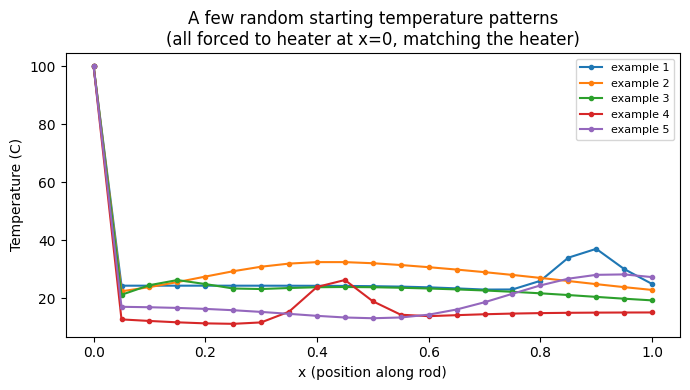

In [ ]:
demo_rng = np.random.default_rng(7)

fig, ax = plt.subplots(figsize=(7, 4))
for i in range(5):
    ic = rand_ic(demo_rng)
    ax.plot(sensor_x, ic, marker='o', markersize=3, label=f'example {i+1}')
ax.set_xlabel('x (position along rod)')
ax.set_ylabel('Temperature (C)')
ax.set_title('A few random starting temperature patterns\n(all forced to heater at x=0, matching the heater)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
num_nodes = 101
time_step = 0.5
x_nodes = np.linspace(0, L, num_nodes)
h = x_nodes[1] - x_nodes[0]

M = np.zeros((num_nodes, num_nodes))
K = np.zeros((num_nodes, num_nodes))
M_local = (h / 6.0) * np.array([[2, 1], [1, 2]]) # M controls how neighboring points influence each other
K_local = (1.0 / h) * np.array([[1, -1], [-1, 1]]) # K controls how heat flows from high to low
for e in range(num_nodes - 1):
    nodes = [e, e + 1]
    for a in range(2):
        for b in range(2):
            M[nodes[a], nodes[b]] += M_local[a, b]
            K[nodes[a], nodes[b]] += K_local[a, b]


def run_fem(ic_vals, alpha, times):
    n_dt = int(max_time / time_step) # number of times
    dt = max_time / n_dt # new timestep
    A = M + alpha * dt * K
    A[0, :] = 0.0
    A[0, 0] = 1.0
    A_factored = lu_factor(A)

    T = np.interp(x_nodes, sensor_x, ic_vals) # ic
    T[0] = heater

    times = sorted(times)
    results = {}
    t_current = 0.0
    next_idx = 0
    if times and times[0] <= 1e-9:
        results[times[0]] = T.copy()
        next_idx = 1

    for step in range(n_dt):
        rhs = M @ T
        rhs[0] = heater
        T = lu_solve(A_factored, rhs)
        t_current += dt
        while next_idx < len(times) and t_current >= times[next_idx] - 1e-6:
            results[times[next_idx]] = T.copy()
            next_idx += 1

    return results

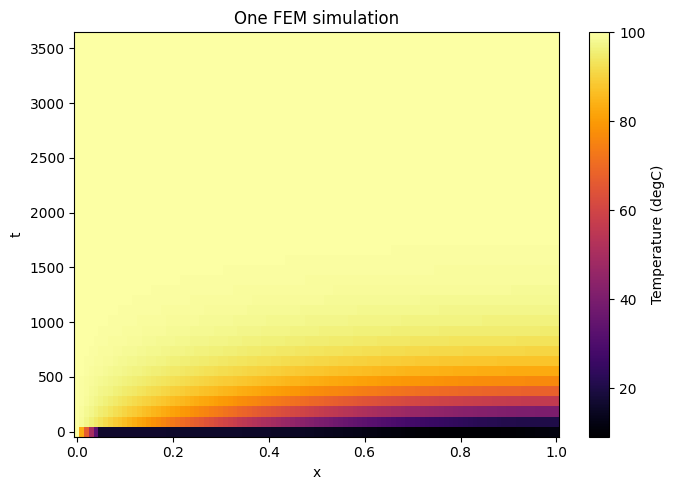

In [ ]:
demo_rng2 = np.random.default_rng(3)
ic_demo = rand_ic(demo_rng2)
alpha_demo = rand_mat(demo_rng2)
times_demo = np.linspace(0, max_time, 40)
fem_demo = run_fem(ic_demo, alpha_demo, times_demo)

sorted_times = sorted(fem_demo.keys())
T_grid = np.array([fem_demo[t] for t in sorted_times])  # (n_times, num_nodes)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.pcolormesh(x_nodes, sorted_times, T_grid, shading='auto', cmap='inferno')
ax.set_xlabel('x')
ax.set_ylabel('t')
ax.set_title('One FEM simulation')
fig.colorbar(im, ax=ax, label='Temperature (degC)')
plt.tight_layout()
plt.show()

In [ ]:
P = 64  # size of branch/trunk space

class DeepONet(nn.Module):
    def __init__(self, sensors=sensors, p=P):
        super().__init__()
        self.branch = nn.Sequential(
            nn.Linear(sensors + 1, 128), nn.Tanh(),
            nn.Linear(128, 128), nn.Tanh(),
            nn.Linear(128, p),
        )
        self.trunk = nn.Sequential(
            nn.Linear(2, 128), nn.Tanh(),
            nn.Linear(128, 128), nn.Tanh(),
            nn.Linear(128, p), nn.Tanh(),
        )
        self.bias = nn.Parameter(torch.zeros(1))

    def forward(self, ic_batch, alpha_batch, x_batch, t_batch):
        alpha_norm = (alpha_batch - alphas[0]) / (alphas[1] - alphas[0])
        branch_in = torch.cat([ic_batch, alpha_norm.unsqueeze(-1)], dim=-1)
        branch_out = self.branch(branch_in)
        t_norm = t_batch / max_time
        trunk_in = torch.stack([x_batch, t_norm], dim=-1)
        trunk_out = self.trunk(trunk_in)
        return (branch_out * trunk_out).sum(dim=-1) + self.bias

In [ ]:
n_samples = 80

def extract(ic_vals, alpha, rng):
    times = sorted(rng.uniform(0, max_time, size=12).tolist() + [0.0])
    fem_result = run_fem(ic_vals, alpha, times)

    egs = []
    for _ in range(n_samples):
        t_val = rng.choice(list(fem_result.keys()))
        x_idx = rng.integers(0, num_nodes)
        x_val = x_nodes[x_idx]
        T_true = fem_result[t_val][x_idx]
        egs.append((ic_vals, alpha, x_val, t_val, T_true))
    return egs


def convert(egs):
    ic = torch.tensor(np.array([e[0] for e in egs]), dtype=torch.float32)
    alpha_t = torch.tensor([e[1] for e in egs], dtype=torch.float32)
    x_t = torch.tensor([e[2] for e in egs], dtype=torch.float32)
    t_t = torch.tensor([e[3] for e in egs], dtype=torch.float32)
    T_t = torch.tensor([e[4] for e in egs], dtype=torch.float32)
    return ic, alpha_t, x_t, t_t, T_t

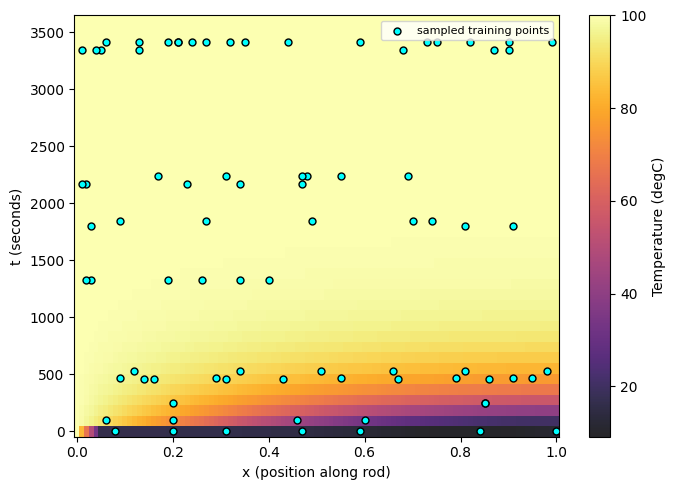

In [ ]:
demo_egs = extract(ic_demo, alpha_demo, np.random.default_rng(11))
ex_t = [e[3] for e in demo_egs]
ex_x = [e[2] for e in demo_egs]

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.pcolormesh(x_nodes, sorted_times, T_grid, shading='auto', cmap='inferno', alpha=0.85)
ax.scatter(ex_x, ex_t, c='cyan', edgecolor='black', s=25, label='sampled training points', zorder=5)
ax.set_xlabel('x (position along rod)')
ax.set_ylabel('t (seconds)')
ax.legend(loc='upper right', fontsize=8)
fig.colorbar(im, ax=ax, label='Temperature (degC)')
plt.tight_layout()
plt.show()

In [ ]:
rng = np.random.default_rng(42)

inits = 60
choices = 60
tests = 15

def makelist(n, rng):
    return [(rand_ic(rng), rand_mat(rng)) for _ in range(n)]

init_pool = makelist(inits, rng)
choice_pool = makelist(choices, rng)   # not simulated yet
test_pool = makelist(tests, rng)

print("Simulating inits")
train_egs = []
for ic, alpha in init_pool:
    train_egs.extend(extract(ic, alpha, rng))

print(f"Simulating tests")
femcache = {}
for i, (ic, alpha) in enumerate(test_pool):
    times = list(np.linspace(0, max_time, 8))
    femcache[i] = run_fem(ic, alpha, times)

Simulating inits
Simulating tests


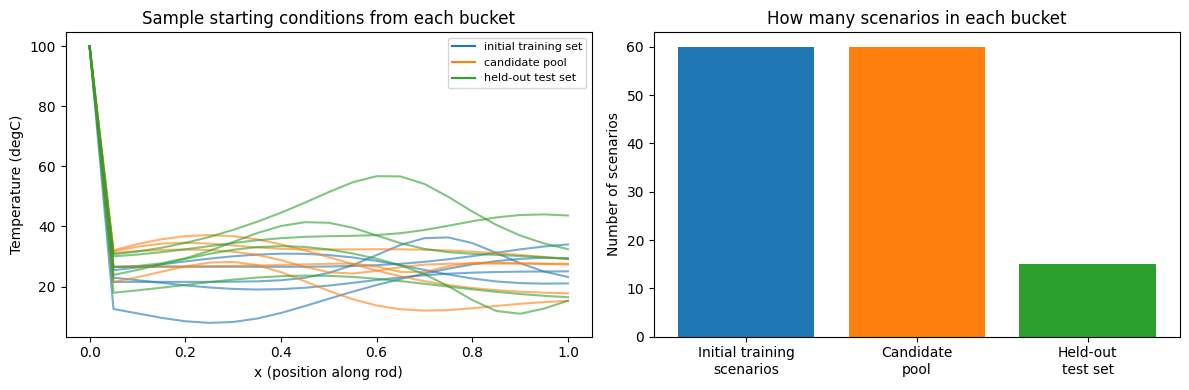

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ic, _ in init_pool[:5]:
    axes[0].plot(sensor_x, ic, color='tab:blue', alpha=0.6)
for ic, _ in choice_pool[:5]:
    axes[0].plot(sensor_x, ic, color='tab:orange', alpha=0.6)
for ic, _ in test_pool[:5]:
    axes[0].plot(sensor_x, ic, color='tab:green', alpha=0.6)
axes[0].plot([], [], color='tab:blue', label='initial training set')
axes[0].plot([], [], color='tab:orange', label='candidate pool')
axes[0].plot([], [], color='tab:green', label='held-out test set')
axes[0].set_xlabel('x (position along rod)')
axes[0].set_ylabel('Temperature (degC)')
axes[0].set_title('Sample starting conditions from each bucket')
axes[0].legend(fontsize=8)

bucket_names = ['Initial training\nscenarios', 'Candidate\npool', 'Held-out\ntest set']
bucket_counts = [len(init_pool), len(choice_pool), len(test_pool)]
axes[1].bar(bucket_names, bucket_counts, color=['tab:blue', 'tab:orange', 'tab:green'])
axes[1].set_ylabel('Number of scenarios')
axes[1].set_title('How many scenarios in each bucket')

plt.tight_layout()
plt.show()

In [ ]:
ens_n = 3
w_data = 1.0
w_phy = 0.02

def train1(model, train_egs, pool, epochs, lr=2e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-5)
    ic_t, alpha_t, x_t, t_t, T_t = convert(train_egs)
    for epoch in range(epochs):
        opt.zero_grad()
        pred = model(ic_t, alpha_t, x_t, t_t)
        data_loss = torch.mean((pred - T_t) ** 2)

        # ---- physics residual on a random scenario from the pool ----
        ic_np, alpha_val = pool[np.random.randint(len(pool))]
        n_phys = 64
        ic_phys = torch.tensor(np.tile(ic_np, (n_phys, 1)), dtype=torch.float32)
        alpha_phys = torch.full((n_phys,), alpha_val, dtype=torch.float32)
        x_phys = (torch.rand(n_phys) * L).requires_grad_(True)
        t_phys = (torch.rand(n_phys) * max_time).requires_grad_(True)

        T_phys = model(ic_phys, alpha_phys, x_phys, t_phys)
        dT_dx = torch.autograd.grad(T_phys, x_phys, torch.ones_like(T_phys), create_graph=True)[0]
        d2T_dx2 = torch.autograd.grad(dT_dx, x_phys, torch.ones_like(dT_dx), create_graph=True)[0]
        dT_dt = torch.autograd.grad(T_phys, t_phys, torch.ones_like(T_phys), create_graph=True)[0]
        residual = dT_dt - alpha_val * d2T_dx2
        physics_loss = torch.mean(residual ** 2)

        loss = w_data * data_loss + w_phy * physics_loss
        loss.backward()
        opt.step()
        sched.step()
        if epoch % 500 == 0:
          print(f"Epoch {epoch}: data loss = {data_loss.item():.4f}, physics loss = {physics_loss.item():.4f}")

    return model


def train2(train_egs, pool, epochs, ens_n=ens_n, existing=None):
    models = []
    for i in range(ens_n):
        if existing is not None:
            model = existing[i]
        else:
            torch.manual_seed(100 + i)
            model = DeepONet()
        model = train1(model, train_egs, pool, epochs)
        models.append(model)
    return models

### 7.1 Initial ensemble training

In [ ]:
epoch_n = 1500

ensemble = train2(train_egs, init_pool, epochs=epoch_n)
print(f"Trained {ens_n} models on {len(train_egs)} egs")

Epoch 0: data loss = 8387.6611, physics loss = 0.0000
Epoch 500: data loss = 36.4400, physics loss = 0.0041
Epoch 1000: data loss = 24.8684, physics loss = 0.0155
Epoch 0: data loss = 8347.2432, physics loss = 0.0000
Epoch 500: data loss = 27.2607, physics loss = 0.0022
Epoch 1000: data loss = 15.9558, physics loss = 0.0013
Epoch 0: data loss = 8421.1025, physics loss = 0.0000
Epoch 500: data loss = 31.3539, physics loss = 0.0005
Epoch 1000: data loss = 19.7055, physics loss = 0.2156
Trained 3 models on 4800 egs


In [ ]:
def predict(models, ic_batch, alpha_batch, x_batch, t_batch):
    with torch.no_grad():
        preds = torch.stack([m(ic_batch, alpha_batch, x_batch, t_batch) for m in models])
    return preds.mean(dim=0), preds.std(dim=0)


def uncertain(models, ic, alpha, n_query=30):
    ic_t = torch.tensor(np.tile(ic, (n_query, 1)), dtype=torch.float32)
    alpha_t = torch.full((n_query,), alpha, dtype=torch.float32)
    x_t = torch.rand(n_query) * L
    t_t = torch.rand(n_query) * max_time
    _, std = predict(models, ic_t, alpha_t, x_t, t_t)
    return std.mean().item()


def eval(models):
    errors = []
    for i, (ic, alpha) in enumerate(test_pool):
        fem_result = femcache[i]
        for t_val, T_field in fem_result.items():
            n_sample = 10
            idxs = np.random.choice(num_nodes, n_sample, replace=False)
            ic_t = torch.tensor(np.tile(ic, (n_sample, 1)), dtype=torch.float32)
            alpha_t = torch.full((n_sample,), alpha, dtype=torch.float32)
            x_t = torch.tensor(x_nodes[idxs], dtype=torch.float32)
            t_t = torch.full((n_sample,), float(t_val), dtype=torch.float32)
            pred, _ = predict(models, ic_t, alpha_t, x_t, t_t)
            true_vals = T_field[idxs]
            errors.append(np.abs(pred.numpy() - true_vals))
    errors = np.concatenate(errors)
    return errors.mean(), errors.max()


mean_err, max_err = eval(ensemble)
print(f"mean error = {mean_err:.3f} degC, max error = {max_err:.3f} degC")

mean error = 2.312 degC, max error = 30.030 degC


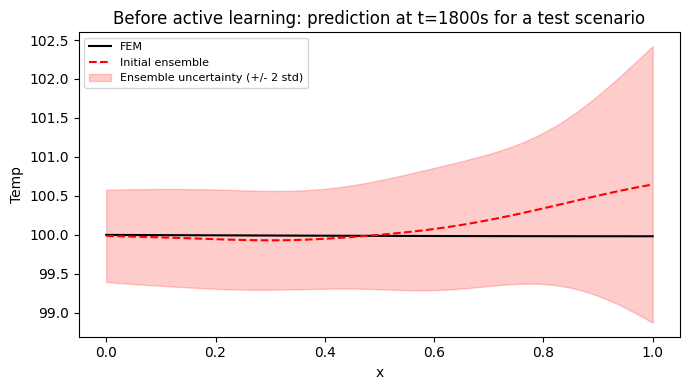

In [ ]:
demo_test_idx = 0
demo_ic2, demo_alpha2 = test_pool[demo_test_idx]
demo_t2 = max_time * 0.5

x_query2 = torch.tensor(x_nodes, dtype=torch.float32)
ic_query2 = torch.tensor(np.tile(demo_ic2, (num_nodes, 1)), dtype=torch.float32)
alpha_query2 = torch.full((num_nodes,), demo_alpha2, dtype=torch.float32)
t_query2 = torch.full((num_nodes,), demo_t2, dtype=torch.float32)

mean_pred0, std_pred0 = predict(ensemble, ic_query2, alpha_query2, x_query2, t_query2)
true_field0 = run_fem(demo_ic2, demo_alpha2, [demo_t2])[demo_t2]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x_nodes, true_field0, 'k-', label='FEM')
ax.plot(x_nodes, mean_pred0.numpy(), 'r--', label='Initial ensemble')
ax.fill_between(x_nodes, (mean_pred0 - 2*std_pred0).numpy(), (mean_pred0 + 2*std_pred0).numpy(),
                 alpha=0.2, color='red', label='Ensemble uncertainty (+/- 2 std)')
ax.set_xlabel('x')
ax.set_ylabel('Temp')
ax.set_title(f'Before active learning: prediction at t={demo_t2:.0f}s for a test scenario')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
rounds = 4
k = 6
epoch_n2 = 250

def act_learn(strat, seed_offset):
    torch.manual_seed(200 + seed_offset)
    models = train2(train_egs, init_pool, epochs=epoch_n, ens_n=ens_n)

    current_egs = list(train_egs)
    remains = list(choice_pool)
    hist = []

    mean_err, _ = eval(models)
    hist.append({"round": 0, "size": len(current_egs), "err": mean_err})
    print(f"[{strat}] round 0 test mean error: {mean_err:.3f} degC")

    for round_idx in range(1, rounds + 1):
        if strat == "uncertainty":
            scores = [uncertain(models, ic, alpha) for ic, alpha in remains]
            order = np.argsort(scores)[::-1]
            chosen_idx = order[:k]
        else:
            chosen_idx = np.random.choice(len(remains), size=k, replace=False)

        chosen = [remains[i] for i in chosen_idx]
        remains = [s for j, s in enumerate(remains) if j not in set(chosen_idx)]

        for ic, alpha in chosen:
            current_egs.extend(extract(ic, alpha, rng))

        models = train2(current_egs, init_pool + chosen, epochs=epoch_n2,
                                 ens_n=ens_n, existing=models)

        mean_err, _ = eval(models)
        hist.append({"round": round_idx, "size": len(current_egs), "err": mean_err})
        print(f"[{strat}] round {round_idx} dataset size {len(current_egs)} test mean error: {mean_err:.3f} degC")

    return models, hist


print("Uncertainty-guided active learning")
al_models, al_hist = act_learn("uncertainty", seed_offset=0)

print()
print("Random-selection baseline")
base_models, base_hist = act_learn("random", seed_offset=1)

bl_models, bl_hist = base_models, base_hist
al_errors = [h["err"] for h in al_hist]
bl_errors = [h["err"] for h in bl_hist]

Uncertainty-guided active learning
Epoch 0: data loss = 8387.6611, physics loss = 0.0000
Epoch 500: data loss = 36.4400, physics loss = 0.0069
Epoch 1000: data loss = 24.8684, physics loss = 0.0068
Epoch 0: data loss = 8347.2432, physics loss = 0.0000
Epoch 500: data loss = 27.2622, physics loss = 0.0020
Epoch 1000: data loss = 15.9588, physics loss = 0.0017
Epoch 0: data loss = 8421.1025, physics loss = 0.0000
Epoch 500: data loss = 31.3539, physics loss = 0.0019
Epoch 1000: data loss = 19.7159, physics loss = 0.2869
[uncertainty] round 0 test mean error: 2.380 degC
Epoch 0: data loss = 23.1885, physics loss = 0.0031
Epoch 0: data loss = 16.2462, physics loss = 0.0300
Epoch 0: data loss = 18.2999, physics loss = 0.0008
[uncertainty] round 1 dataset size 5280 test mean error: 2.261 degC
Epoch 0: data loss = 20.9836, physics loss = 0.1292
Epoch 0: data loss = 13.9821, physics loss = 0.1644
Epoch 0: data loss = 19.8227, physics loss = 0.1175
[uncertainty] round 2 dataset size 5760 test m

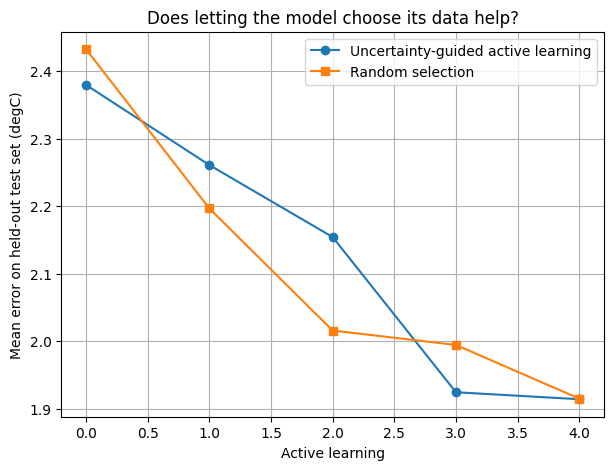

Final uncertainty-guided error: 1.914 degC
Final random-base error:    1.915 degC


In [ ]:
al_rounds = [h["round"] for h in al_hist]
al_errors = [h["err"] for h in al_hist]
bl_errors = [h["err"] for h in base_hist]

plt.figure(figsize=(7, 5))
plt.plot(al_rounds, al_errors, marker='o', label='Uncertainty-guided active learning')
plt.plot(al_rounds, bl_errors, marker='s', label='Random selection')
plt.xlabel('Active learning')
plt.ylabel('Mean error on held-out test set (degC)')
plt.title('Does letting the model choose its data help?')
plt.legend()
plt.grid(True)
plt.show()

print(f"Final uncertainty-guided error: {al_errors[-1]:.3f} degC")
print(f"Final random-base error:    {bl_errors[-1]:.3f} degC")

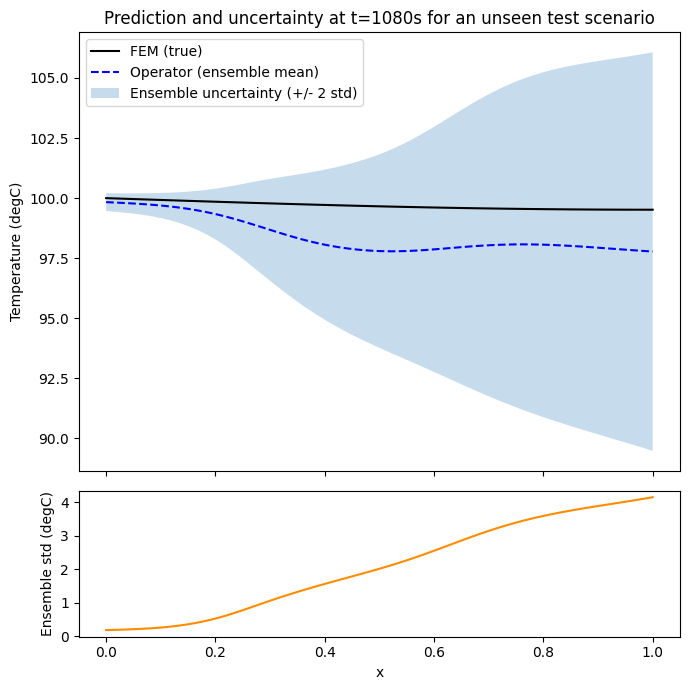

In [ ]:
demo_ic, demo_alpha = test_pool[0]
demo_t = max_time * 0.3

x_query = torch.tensor(x_nodes, dtype=torch.float32)
ic_query = torch.tensor(np.tile(demo_ic, (num_nodes, 1)), dtype=torch.float32)
alpha_query = torch.full((num_nodes,), demo_alpha, dtype=torch.float32)
t_query = torch.full((num_nodes,), demo_t, dtype=torch.float32)

mean_pred, std_pred = predict(al_models, ic_query, alpha_query, x_query, t_query)
true_field = run_fem(demo_ic, demo_alpha, [demo_t])[demo_t]

fig, axes = plt.subplots(2, 1, figsize=(7, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

axes[0].plot(x_nodes, true_field, 'k-', label='FEM (true)')
axes[0].plot(x_nodes, mean_pred.numpy(), 'b--', label='Operator (ensemble mean)')
axes[0].fill_between(x_nodes, (mean_pred - 2*std_pred).numpy(), (mean_pred + 2*std_pred).numpy(),
                       alpha=0.25, label='Ensemble uncertainty (+/- 2 std)')
axes[0].set_ylabel('Temperature (degC)')
axes[0].legend()
axes[0].set_title(f'Prediction and uncertainty at t={demo_t:.0f}s for an unseen test scenario')

axes[1].plot(x_nodes, std_pred.numpy(), color='darkorange')
axes[1].set_ylabel('Ensemble std (degC)')
axes[1].set_xlabel('x')

plt.tight_layout()
plt.show()

### 8. Comparing against the analytical solution

For a **uniform initial condition** (rod at a flat 20°C, heater end forced to 100°C) with the far end insulated (zero-flux — exactly what the FEM's natural boundary condition already gives at `x=L`), the heat equation has a closed-form Fourier series solution:

$$T(x,t) = 100 - \frac{320}{\pi}\sum_{n=0}^{\infty} \frac{\sin\!\left(\dfrac{(2n+1)\pi x}{2L}\right)\exp\!\left(-\alpha t\left(\dfrac{(2n+1)\pi}{2L}\right)^{2}\right)}{2n+1}$$

This is a genuine out-of-sample test: every training scenario had random Gaussian bumps in the initial condition, so a flat 20°C profile is a case the operator never saw during training/active learning. We'll query the final active-learned ensemble (`al_models`) on this scenario across a full `(x, t)` grid and compare directly to the analytical field.

Mean absolute error: 0.6167 degC
Max absolute error:  41.4458 degC
RMSE:                1.7521 degC


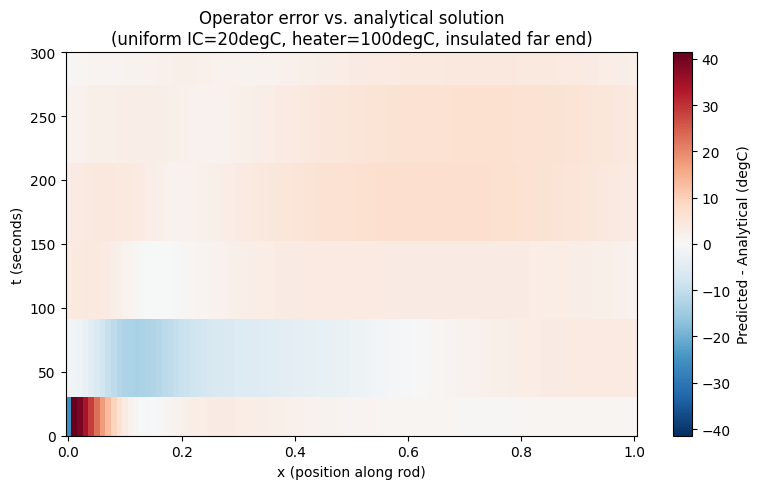

In [ ]:
def analytical_solution(x_grid, t_grid, alpha, L=L, heater=heater, T0=20.0, n_terms=200):
    """Closed-form 1D heat equation solution for a uniform IC=T0, fixed T=heater at x=0,
    insulated (zero-flux) end at x=L.

    T(x,t) = heater - (4/pi)*(heater - T0) * sum_{n=0}^inf sin((2n+1)*pi*x/(2L)) *
             exp(-alpha*t*((2n+1)*pi/(2L))**2) / (2n+1)

    With heater=100, T0=20 this is exactly:
    T(x,t) = 100 - 320/pi * sum_{n=0}^inf sin((2n+1)*pi*x/(2L)) * exp(-alpha*t*((2n+1)*pi/(2L))**2) / (2n+1)
    """
    n = np.arange(n_terms)
    coeff = 2 * n + 1
    lam = coeff * np.pi / (2 * L)  # shape (n_terms,)

    # x_grid, t_grid: 2D arrays of matching shape (n_t, n_x)
    sin_term = np.sin(lam[:, None, None] * x_grid[None, :, :])
    exp_term = np.exp(-alpha * t_grid[None, :, :] * lam[:, None, None] ** 2)
    series = (sin_term * exp_term) / coeff[:, None, None]

    return heater - (4.0 / np.pi) * (heater - T0) * series.sum(axis=0)


# --- build a uniform IC=20degC scenario (matches the analytical solution's assumptions) ---
T0_val = 20.0
alpha_val = (alphas[0] + alphas[1]) / 2  # a material in the middle of the trained range

ic_uniform = np.full(sensors, T0_val)
ic_uniform[0] = heater  # heater end, same convention as rand_ic

# --- build the (x, t) grid ---
n_t = 60
t_vals = np.linspace(0, max_time, n_t)
X_grid, T_grid_mesh = np.meshgrid(x_nodes, t_vals)  # both shape (n_t, num_nodes)

# --- analytical field ---
analytical_field = analytical_solution(X_grid, T_grid_mesh, alpha_val)

# --- operator (PINN) predictions on the same grid ---
n_x = num_nodes
x_flat = torch.tensor(X_grid.flatten(), dtype=torch.float32)
t_flat = torch.tensor(T_grid_mesh.flatten(), dtype=torch.float32)
ic_flat = torch.tensor(np.tile(ic_uniform, (n_t * n_x, 1)), dtype=torch.float32)
alpha_flat = torch.full((n_t * n_x,), alpha_val, dtype=torch.float32)

pred_mean, pred_std = predict(al_models, ic_flat, alpha_flat, x_flat, t_flat)
pinn_field = pred_mean.numpy().reshape(n_t, n_x)

# --- error ---
error_field = pinn_field - analytical_field
abs_max = np.max(np.abs(error_field))

print(f"Mean absolute error: {np.mean(np.abs(error_field)):.4f} degC")
print(f"Max absolute error:  {np.max(np.abs(error_field)):.4f} degC")
print(f"RMSE:                {np.sqrt(np.mean(error_field**2)):.4f} degC")

# --- heatmap of PINN - analytical error over (x, t) ---
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.pcolormesh(x_nodes, t_vals, error_field, shading='auto', cmap='RdBu_r',
                    vmin=-abs_max, vmax=abs_max)
ax.set_xlabel('x (position along rod)')
ax.set_ylabel('t (seconds)')
ax.set_ylim(0, 300)
ax.set_title('Operator error vs. analytical solution\n(uniform IC=20degC, heater=100degC, insulated far end)')
fig.colorbar(im, ax=ax, label='Predicted - Analytical (degC)')
plt.tight_layout()
plt.show()

In [ ]:
# ---- MAE summaries ----
five_min = 5 * 60  # seconds

# 1) MAE over the entire simulation (all t, all x)
mae_full = np.mean(np.abs(error_field))

# 2) MAE restricted to the first 5 minutes (all x)
mask_5min = t_vals <= five_min
mae_5min = np.mean(np.abs(error_field[mask_5min, :]))

# 3) MAE within the first 5 minutes, split into 5 equal x-segments of width 0.2
seg_width = 0.2
n_segs = 5
seg_mae = []
for i in range(n_segs):
    x_lo, x_hi = i * seg_width, (i + 1) * seg_width
    if i == n_segs - 1:
        x_mask = (x_nodes >= x_lo) & (x_nodes <= x_hi)  # include x=1.0 in the last segment
    else:
        x_mask = (x_nodes >= x_lo) & (x_nodes < x_hi)
    seg_error = error_field[np.ix_(mask_5min, x_mask)]
    seg_mae.append(np.mean(np.abs(seg_error)))

print(f"MAE over entire simulation:       {mae_full:.4f} degC")
print(f"MAE over first 5 minutes (all x): {mae_5min:.4f} degC")
print("MAE over first 5 minutes, by x-segment:")
for i, m in enumerate(seg_mae):
    print(f"  segment {i+1}  x in [{i*seg_width:.1f}, {(i+1)*seg_width:.1f}]:  {m:.4f} degC")

MAE over entire simulation:       0.6167 degC
MAE over first 5 minutes (all x): 4.0495 degC
MAE over first 5 minutes, by x-segment:
  segment 1  x in [0.0, 0.2]:  5.8666 degC
  segment 2  x in [0.2, 0.4]:  3.3906 degC
  segment 3  x in [0.4, 0.6]:  3.7434 degC
  segment 4  x in [0.6, 0.8]:  3.7925 degC
  segment 5  x in [0.8, 1.0]:  3.4849 degC


### 9. Extension: nonlinear thermal conductivity, alpha(T)

Everything above uses a constant diffusivity alpha per scenario. Real materials don't work that way &mdash; conductivity
(and therefore alpha = k / (rho*c_p)) typically depends on temperature. For most metals, conductivity *drops* as
temperature rises (phonon scattering increases), so we model this with a simple linear law:

$$\alpha(T) = \alpha_0 \left(1 + \beta (T - T_{ref})\right)$$

where alpha_0 is the same base diffusivity used everywhere else in this notebook, beta is a material sensitivity
coefficient (negative for a gold-like metal), and T_ref is a reference temperature (taken as the cold IC baseline, 20C).

This single change breaks two things that the rest of the notebook relies on:
- **No closed-form solution.** Section 8's analytical solution comes from separation of variables, which requires
  alpha to be constant. Once alpha depends on T, the PDE is nonlinear and no such solution exists.
- **FEM gets more expensive.** The linear system A @ T = b in `run_fem` can be factored once per problem (`lu_factor`)
  and reused at every timestep. When alpha depends on the unknown T, A itself depends on T, so each timestep needs an
  iterative solve (Picard fixed-point iteration below) instead of one triangular solve.

This section builds a nonlinear FEM reference solver, compares it against the existing linear FEM, and extends the
operator's physics-residual loss to the nonlinear PDE so the operator can be trained directly against it.

In [ ]:
def alpha_of_T(T, alpha0, beta, T_ref=20.0):
    """Linear temperature-dependent diffusivity: alpha0 at T_ref, decreasing (beta<0) or
    increasing (beta>0) away from it."""
    return alpha0 * (1.0 + beta * (T - T_ref))


def assemble_K_nonlinear(T_field, alpha0, beta, T_ref=20.0):
    """Rebuild the stiffness matrix with a per-element alpha evaluated at that element's
    average temperature. Same element loop as the constant-alpha assembly in an earlier cell,
    but alpha is no longer a single scalar multiplying the whole matrix."""
    K_nl = np.zeros((num_nodes, num_nodes))
    for e in range(num_nodes - 1):
        nodes = [e, e + 1]
        T_avg = 0.5 * (T_field[nodes[0]] + T_field[nodes[1]])
        alpha_e = alpha_of_T(T_avg, alpha0, beta, T_ref)
        for a in range(2):
            for b in range(2):
                K_nl[nodes[a], nodes[b]] += alpha_e * K_local[a, b]
    return K_nl


def run_fem_nonlinear(ic_vals, alpha0, beta, times, T_ref=20.0, max_picard=15, tol=1e-4):
    """Same time-stepping scheme as run_fem, but with a Picard fixed-point loop inside each
    timestep: guess T, build A(T), solve, check convergence, repeat. Returns the same
    {time: field} dict as run_fem, plus the total Picard iteration count so cost can be compared."""
    n_dt = int(max_time / time_step)
    dt = max_time / n_dt

    T = np.interp(x_nodes, sensor_x, ic_vals)
    T[0] = heater

    times = sorted(times)
    results = {}
    t_current = 0.0
    next_idx = 0
    if times and times[0] <= 1e-9:
        results[times[0]] = T.copy()
        next_idx = 1

    total_iters = 0
    for step in range(n_dt):
        rhs = M @ T
        rhs[0] = heater

        T_guess = T.copy()
        for picard_iter in range(max_picard):
            K_nl = assemble_K_nonlinear(T_guess, alpha0, beta, T_ref)
            A = M + dt * K_nl
            A[0, :] = 0.0
            A[0, 0] = 1.0
            T_new = np.linalg.solve(A, rhs)
            total_iters += 1
            if np.max(np.abs(T_new - T_guess)) < tol:
                T_guess = T_new
                break
            T_guess = T_new
        T = T_guess

        t_current += dt
        while next_idx < len(times) and t_current >= times[next_idx] - 1e-6:
            results[times[next_idx]] = T.copy()
            next_idx += 1

    return results, total_iters

alpha0 = 1.27e-03, beta = -0.003
linear FEM:    0.159s, 1 solve/timestep (7200 solves total)
nonlinear FEM: 8.419s, 13198 solves total (1.83 Picard iters/timestep on average)
=> nonlinear FEM took 53.0x longer than linear FEM for the same scenario


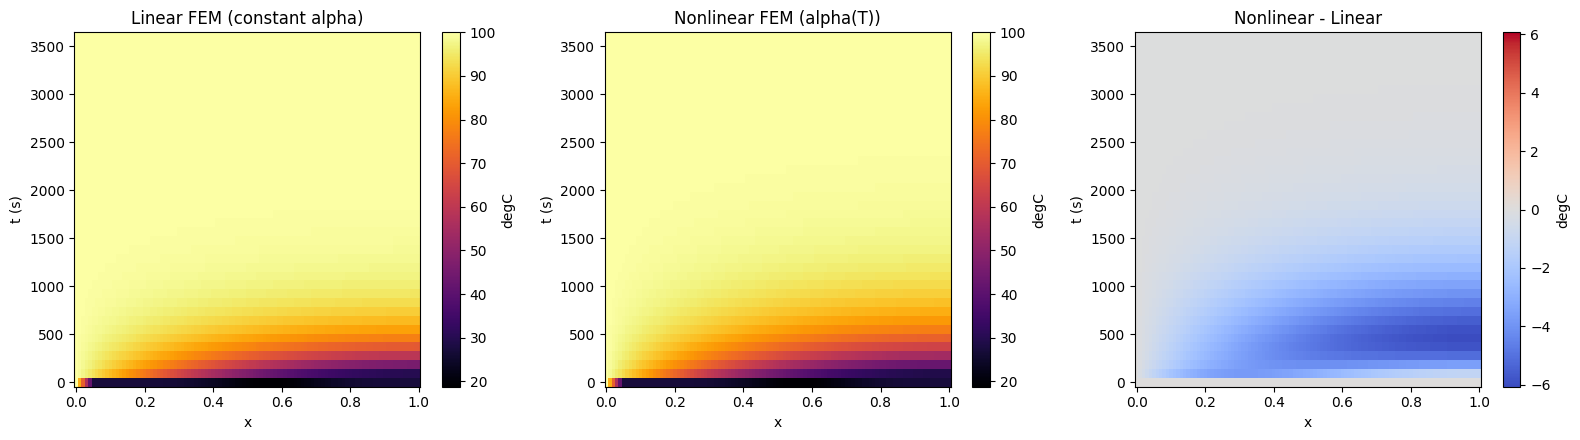

Mean |nonlinear - linear| FEM error across the rod:
  t=  60s: 1.920 degC
  t= 150s: 3.041 degC
  t= 300s: 3.994 degC
  t= 600s: 3.799 degC


In [ ]:
# ---- linear vs nonlinear FEM: accuracy and cost comparison ----
import time

nl_rng = np.random.default_rng(5)
ic_nl = rand_ic(nl_rng)
alpha0_nl = rand_mat(nl_rng)
beta_nl = -0.003  # gold-like: conductivity falls as temperature rises

compare_times = sorted(np.linspace(0, max_time, 40).tolist())

t0 = time.time()
lin_result = run_fem(ic_nl, alpha0_nl, compare_times)
t1 = time.time()
nl_result, nl_iters = run_fem_nonlinear(ic_nl, alpha0_nl, beta_nl, compare_times)
t2 = time.time()

n_steps = int(max_time / time_step)
print(f"alpha0 = {alpha0_nl:.2e}, beta = {beta_nl}")
print(f"linear FEM:    {t1 - t0:.3f}s, 1 solve/timestep ({n_steps} solves total)")
print(f"nonlinear FEM: {t2 - t1:.3f}s, {nl_iters} solves total "
      f"({nl_iters / n_steps:.2f} Picard iters/timestep on average)")
print(f"=> nonlinear FEM took {(t2 - t1) / (t1 - t0):.1f}x longer than linear FEM "
      f"for the same scenario")

lin_grid = np.array([lin_result[t] for t in compare_times])
nl_grid = np.array([nl_result[t] for t in compare_times])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
im0 = axes[0].pcolormesh(x_nodes, compare_times, lin_grid, shading='auto', cmap='inferno')
axes[0].set_title('Linear FEM (constant alpha)')
axes[0].set_xlabel('x'); axes[0].set_ylabel('t (s)')
fig.colorbar(im0, ax=axes[0], label='degC')

im1 = axes[1].pcolormesh(x_nodes, compare_times, nl_grid, shading='auto', cmap='inferno')
axes[1].set_title('Nonlinear FEM (alpha(T))')
axes[1].set_xlabel('x'); axes[1].set_ylabel('t (s)')
fig.colorbar(im1, ax=axes[1], label='degC')

diff_grid = nl_grid - lin_grid
im2 = axes[2].pcolormesh(x_nodes, compare_times, diff_grid, shading='auto', cmap='coolwarm',
                          vmin=-np.max(np.abs(diff_grid)), vmax=np.max(np.abs(diff_grid)))
axes[2].set_title('Nonlinear - Linear')
axes[2].set_xlabel('x'); axes[2].set_ylabel('t (s)')
fig.colorbar(im2, ax=axes[2], label='degC')

plt.tight_layout()
plt.show()
snapshot_times = [60, 150, 300, 600]
lin_snap = run_fem(ic_nl, alpha0_nl, snapshot_times)
nl_snap, _ = run_fem_nonlinear(ic_nl, alpha0_nl, beta_nl, snapshot_times)

print("Mean |nonlinear - linear| FEM error across the rod:")
for t_val in snapshot_times:
    mean_err = np.mean(np.abs(nl_snap[t_val] - lin_snap[t_val]))
    print(f"  t={t_val:>4}s: {mean_err:.3f} degC")

**Reading the comparison above:** with beta negative, the rod runs *hotter* than the linear
prediction while it's still actively heating up (lower conductivity near the hot end slows how fast heat
escapes into the cooler interior), and the two solutions converge again near steady state (once the whole
rod approaches the heater temperature, the T-dependent correction term shrinks). The nonlinear solve took
noticeably longer despite Picard converging in only a couple of iterations per timestep on average &mdash; each of those
iterations re-factors and re-solves a full linear system from scratch, instead of the single `lu_factor` reused across
all `n_dt` steps in the linear case. This gap grows further for tighter tolerances, larger beta, or bigger nonlinearities
&mdash; exactly the situations where a PINN's cost stays flat because it never needs a matrix factorization at all.

In [ ]:
# ---- nonlinear physics-residual loss for the operator ----
def nonlinear_physics_loss(model, ic_np, alpha0_val, beta, n_phys=64, T_ref=20.0):
    """Same structure as the physics residual inside train1, but for
    dT/dt = alpha(T) * d2T/dx2 + alpha0*beta * (dT/dx)^2
    instead of dT/dt = alpha * d2T/dx2. The extra term comes from the product rule once alpha
    depends on the unknown field itself (d/dx[alpha(T) dT/dx] = alpha(T) d2T/dx2 + alpha'(T) (dT/dx)^2)."""
    ic_phys = torch.tensor(np.tile(ic_np, (n_phys, 1)), dtype=torch.float32)
    alpha_phys = torch.full((n_phys,), alpha0_val, dtype=torch.float32)
    x_phys = (torch.rand(n_phys) * L).requires_grad_(True)
    t_phys = (torch.rand(n_phys) * max_time).requires_grad_(True)

    T_phys = model(ic_phys, alpha_phys, x_phys, t_phys)
    dT_dx = torch.autograd.grad(T_phys, x_phys, torch.ones_like(T_phys), create_graph=True)[0]
    d2T_dx2 = torch.autograd.grad(dT_dx, x_phys, torch.ones_like(dT_dx), create_graph=True)[0]
    dT_dt = torch.autograd.grad(T_phys, t_phys, torch.ones_like(T_phys), create_graph=True)[0]

    alpha_T = alpha_phys * (1.0 + beta * (T_phys - T_ref))
    dalpha_dT = alpha_phys * beta
    residual = dT_dt - alpha_T * d2T_dx2 - dalpha_dT * (dT_dx ** 2)
    return torch.mean(residual ** 2)


def train1_nonlinear(model, train_egs, pool, beta, epochs, lr=2e-3, T_ref=20.0):
    """Same training loop as train1, but data comes from nonlinear-FEM-generated examples and
    the physics term uses nonlinear_physics_loss. beta is treated as a single known material
    property shared across the pool for this demonstration, rather than a second learned branch
    input -- extending the operator to learn beta per-scenario is a natural next step."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-5)
    ic_t, alpha_t, x_t, t_t, T_t = convert(train_egs)
    for epoch in range(epochs):
        opt.zero_grad()
        pred = model(ic_t, alpha_t, x_t, t_t)
        data_loss = torch.mean((pred - T_t) ** 2)

        ic_np, alpha_val = pool[np.random.randint(len(pool))]
        physics_loss = nonlinear_physics_loss(model, ic_np, alpha_val, beta, T_ref=T_ref)

        loss = w_data * data_loss + w_phy * physics_loss
        loss.backward()
        opt.step()
        sched.step()
        if epoch % 250 == 0:
            print(f"Epoch {epoch}: data loss = {data_loss.item():.4f}, physics loss = {physics_loss.item():.4f}")

    return model

Generating nonlinear-FEM training data (this calls the Picard solver repeatedly, so it's noticeably slower than the linear-FEM data generation earlier in the notebook)...
Epoch 0: data loss = 8195.6055, physics loss = 0.0000
Epoch 250: data loss = 45.3085, physics loss = 0.0005
Epoch 500: data loss = 26.7912, physics loss = 0.0008
Epoch 750: data loss = 15.0755, physics loss = 0.0041
Epoch 1000: data loss = 11.3088, physics loss = 0.0193
Epoch 1250: data loss = 10.1675, physics loss = 0.0007


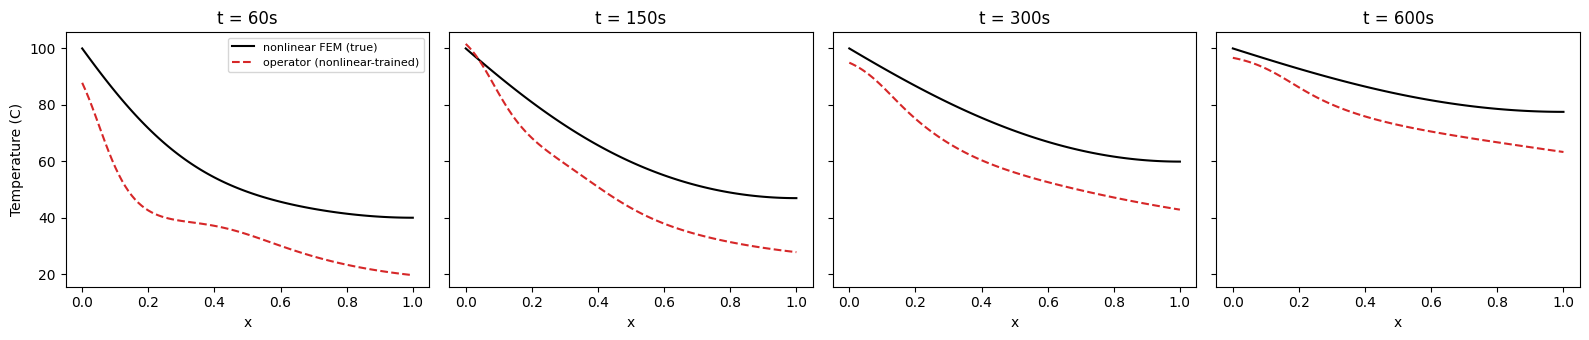

t=60s: MAE vs nonlinear FEM = 19.733 degC
t=150s: MAE vs nonlinear FEM = 14.285 degC
t=300s: MAE vs nonlinear FEM = 13.139 degC
t=600s: MAE vs nonlinear FEM = 9.651 degC
overall MAE across sampled times: 14.202 degC


In [ ]:
# ---- quick proof-of-concept: train one operator on nonlinear-FEM data, check it against
# nonlinear FEM ground truth on a held-out scenario ----
nl_train_rng = np.random.default_rng(21)
nl_pool = [(rand_ic(nl_train_rng), rand_mat(nl_train_rng)) for _ in range(20)]

def extract_nonlinear(ic_vals, alpha0_val, beta, rng):
    times = sorted(rng.uniform(0, max_time, size=12).tolist() + [0.0])
    fem_result, _ = run_fem_nonlinear(ic_vals, alpha0_val, beta, times)
    egs = []
    for _ in range(n_samples):
        t_val = rng.choice(list(fem_result.keys()))
        x_idx = rng.integers(0, num_nodes)
        x_val = x_nodes[x_idx]
        T_true = fem_result[t_val][x_idx]
        egs.append((ic_vals, alpha0_val, x_val, t_val, T_true))
    return egs

print("Generating nonlinear-FEM training data (this calls the Picard solver repeatedly, so it's"
      " noticeably slower than the linear-FEM data generation earlier in the notebook)...")
nl_train_egs = []
for ic_s, a_s in nl_pool:
    nl_train_egs.extend(extract_nonlinear(ic_s, a_s, beta_nl, nl_train_rng))

torch.manual_seed(300)
nl_model = DeepONet()
nl_model = train1_nonlinear(nl_model, nl_train_egs, nl_pool, beta_nl, epochs=1500)

# held-out test scenario
test_rng = np.random.default_rng(99)
ic_test_nl = rand_ic(test_rng)
alpha_test_nl = rand_mat(test_rng)
test_times_nl = [60, 150, 300, 600]
fem_test_nl, _ = run_fem_nonlinear(ic_test_nl, alpha_test_nl, beta_nl, test_times_nl)

fig, axes = plt.subplots(1, len(test_times_nl), figsize=(16, 3.5), sharey=True)
for ax, t_val in zip(axes, test_times_nl):
    x_q = torch.tensor(x_nodes, dtype=torch.float32)
    ic_q = torch.tensor(np.tile(ic_test_nl, (num_nodes, 1)), dtype=torch.float32)
    alpha_q = torch.full((num_nodes,), alpha_test_nl, dtype=torch.float32)
    t_q = torch.full((num_nodes,), float(t_val), dtype=torch.float32)
    with torch.no_grad():
        pred = nl_model(ic_q, alpha_q, x_q, t_q).numpy()
    ax.plot(x_nodes, fem_test_nl[t_val], label='nonlinear FEM (true)', color='black')
    ax.plot(x_nodes, pred, '--', label='operator (nonlinear-trained)', color='tab:red')
    ax.set_title(f't = {t_val}s')
    ax.set_xlabel('x')
axes[0].set_ylabel('Temperature (C)')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

errs = []
for t_val in test_times_nl:
    x_q = torch.tensor(x_nodes, dtype=torch.float32)
    ic_q = torch.tensor(np.tile(ic_test_nl, (num_nodes, 1)), dtype=torch.float32)
    alpha_q = torch.full((num_nodes,), alpha_test_nl, dtype=torch.float32)
    t_q = torch.full((num_nodes,), float(t_val), dtype=torch.float32)
    with torch.no_grad():
        pred = nl_model(ic_q, alpha_q, x_q, t_q).numpy()
    err = np.mean(np.abs(pred - fem_test_nl[t_val]))
    errs.append(err)
    print(f"t={t_val}s: MAE vs nonlinear FEM = {err:.3f} degC")
print(f"overall MAE across sampled times: {np.mean(errs):.3f} degC")

In [ ]:
# ---- speed + accuracy: operator vs linear FEM vs nonlinear FEM ----
import time

test_rng2 = np.random.default_rng(99)
ic_test = rand_ic(test_rng2)
alpha_test = rand_mat(test_rng2)
beta_test = beta_nl
bench_times = [60, 150, 300, 600]

# --- linear FEM ---
t0 = time.time()
lin_bench = run_fem(ic_test, alpha_test, bench_times)
lin_fem_time = time.time() - t0

# --- nonlinear FEM ---
t0 = time.time()
nl_bench, _ = run_fem_nonlinear(ic_test, alpha_test, beta_test, bench_times)
nl_fem_time = time.time() - t0

# --- operator inference (warm up once first so torch's one-time init cost
# doesn't get counted as "inference time") ---
with torch.no_grad():
    _ = nl_model(torch.tensor(np.tile(ic_test, (num_nodes, 1)), dtype=torch.float32),
                 torch.full((num_nodes,), alpha_test, dtype=torch.float32),
                 torch.tensor(x_nodes, dtype=torch.float32),
                 torch.full((num_nodes,), 0.0, dtype=torch.float32))

t0 = time.time()
op_preds = {}
with torch.no_grad():
    for t_val in bench_times:
        x_q = torch.tensor(x_nodes, dtype=torch.float32)
        ic_q = torch.tensor(np.tile(ic_test, (num_nodes, 1)), dtype=torch.float32)
        alpha_q = torch.full((num_nodes,), alpha_test, dtype=torch.float32)
        t_q = torch.full((num_nodes,), float(t_val), dtype=torch.float32)
        op_preds[t_val] = nl_model(ic_q, alpha_q, x_q, t_q).numpy()
op_time = time.time() - t0

print("=== Speed ===")
print(f"linear FEM:     {lin_fem_time:.4f}s")
print(f"nonlinear FEM:  {nl_fem_time:.4f}s")
print(f"operator:       {op_time:.4f}s")
print(f"operator is {lin_fem_time / op_time:.0f}x faster than linear FEM")
print(f"operator is {nl_fem_time / op_time:.0f}x faster than nonlinear FEM")

print("\n=== Accuracy (mean abs error across the rod, operator vs each FEM) ===")
for t_val in bench_times:
    err_vs_lin = np.mean(np.abs(op_preds[t_val] - lin_bench[t_val]))
    err_vs_nl = np.mean(np.abs(op_preds[t_val] - nl_bench[t_val]))
    print(f"t={t_val:>4}s: vs linear FEM = {err_vs_lin:.3f} degC | vs nonlinear FEM = {err_vs_nl:.3f} degC")

overall_vs_lin = np.mean([np.mean(np.abs(op_preds[t] - lin_bench[t])) for t in bench_times])
overall_vs_nl = np.mean([np.mean(np.abs(op_preds[t] - nl_bench[t])) for t in bench_times])
print(f"\noverall MAE vs linear FEM:    {overall_vs_lin:.3f} degC")
print(f"overall MAE vs nonlinear FEM: {overall_vs_nl:.3f} degC")

=== Speed ===
linear FEM:     0.1604s
nonlinear FEM:  8.4273s
operator:       0.0033s
operator is 48x faster than linear FEM
operator is 2518x faster than nonlinear FEM

=== Accuracy (mean abs error across the rod, operator vs each FEM) ===
t=  60s: vs linear FEM = 21.204 degC | vs nonlinear FEM = 19.733 degC
t= 150s: vs linear FEM = 16.598 degC | vs nonlinear FEM = 14.285 degC
t= 300s: vs linear FEM = 16.339 degC | vs nonlinear FEM = 13.139 degC
t= 600s: vs linear FEM = 13.135 degC | vs nonlinear FEM = 9.651 degC

overall MAE vs linear FEM:    16.819 degC
overall MAE vs nonlinear FEM: 14.202 degC


This is a small-scale proof of concept &mdash; a handful of training scenarios and one fixed
beta, meant to check that the nonlinear residual trains correctly and the operator can track a genuinely
nonlinear reference solution, not to draw strong accuracy conclusions. Two natural next steps: (1) run the same
loss-weighting and collocation-density ablations from Section 4 against this nonlinear residual, since the
underweighted-initial-condition failure mode is unrelated to linearity and likely reappears here; and (2) treat
beta as a second branch-network input (alongside alpha0) so a single trained operator generalizes across an entire
*family* of materials rather than one fixed nonlinearity.